# Import packages and configure SWMM path

In [1]:
import os
import random
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spotpy
from spotpy.analyser import get_simulation_fields, get_minlikeindex

from swmm_api import SwmmInput
from swmm_api.input_file.macros import delete_subcatchment
from swmm_api.output_file import VARIABLES
from swmm_api.run_swmm.run_temporary import swmm5_run_temporary

/home/katharina_teuber/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# LangChain / OpenAI-Integration
#from langchain_openai import ChatOpenAI
from langchain_ollama import ChatOllama
from langchain.tools import tool
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
#from langchain.agents import AgentExecutor, create_openai_tools_agent

In [3]:
from langchain_core.messages import convert_to_messages

In [4]:
from langgraph.prebuilt import create_react_agent
from langgraph_supervisor import create_supervisor

In [5]:
import time
import resource

In [6]:
from swmm_api import CONFIG

CONFIG["exe_path"] = "/home/katharina_teuber/Stormwater-Management-Model/build/install/bin/runswmm"
# oder:
# CONFIG.exe_path = "/home/..."

print("exe_path =", CONFIG["exe_path"])
# oder:
print("exe_path_attr =", CONFIG.exe_path)

exe_path = /home/katharina_teuber/Stormwater-Management-Model/build/install/bin/runswmm
exe_path_attr = /home/katharina_teuber/Stormwater-Management-Model/build/install/bin/runswmm


In [7]:
time_start = time.perf_counter()

# Choose LLM-model

In [8]:
llm = ChatOllama(
model="gpt-oss:20b",
temperature=0.1,
base_url="http://localhost:11434")

In [9]:
def pretty_print_message(message, indent=False):
    pretty_message = message.pretty_repr(html=True)
    if not indent:
        print(pretty_message)
        return

    indented = "\n".join("\t" + c for c in pretty_message.split("\n"))
    print(indented)


def pretty_print_messages(update, last_message=False):
    is_subgraph = False
    if isinstance(update, tuple):
        ns, update = update
        # skip parent graph updates in the printouts
        if len(ns) == 0:
            return

        graph_id = ns[-1].split(":")[0]
        print(f"Update from subgraph {graph_id}:")
        print("\n")
        is_subgraph = True

    for node_name, node_update in update.items():
        update_label = f"Update from node {node_name}:"
        if is_subgraph:
            update_label = "\t" + update_label

        print(update_label)
        print("\n")

        # added code - start -
        if not isinstance(node_update, dict):
            # optional: show raw data or skip
            # print("\t(non-dict update, skipping)\n" if is_subgraph else "(non-dict update, skipping)\n")
            continue

        msgs_raw = node_update.get("messages")
        if not msgs_raw:
            # optional: info which data has been skipped
            # print("\t(no messages in update, skipping)\n" if is_subgraph else "(no messages in update, skipping)\n")
            continue
        
        # added code - end -
        messages = convert_to_messages(node_update["messages"])
        if last_message:
            pass
            #messages = messages[-1:]

        for m in messages:
            pretty_print_message(m, indent=is_subgraph)
        print("\n")

In [10]:
# ============================================================
# Experimental design
# ============================================================

# "controlled":
#   identical synthetic model, noise realization and
#   SCE-UA random initialization in every repetition
#
# "stochastic":
#   synthetic model/noise/optimizer are allowed to vary
#   between repetitions as in the original experiment

EXPERIMENT_MODE = "stochastic"

SYNTHETIC_SEED = 501
OPTIMIZER_SEED = 502


# Initial seeds for reproducibility of the complete experiment
random.seed(SYNTHETIC_SEED)
np.random.seed(SYNTHETIC_SEED)

@dataclass
class CalibrationState:
    """common state"""
    inp_path: str | None = None
    node_label: str | None = None

    inp_base: SwmmInput | None = None
    inp_random: SwmmInput | None = None
    ts_base_sim: pd.Series | None = None
    ts_random_sim: pd.Series | None = None
    ts_observation: pd.Series | None = None
    df_results: pd.DataFrame | None = None
    best_index: int | None = None
    best_score: float | None = None

    # Runtime tracking
    swmm_runtime_total_s: float = 0.0
    swmm_simulation_count: int = 0

    calibration_runtime_s: float | None = None
    calibration_swmm_runtime_s: float | None = None
    calibration_swmm_simulations: int | None = None

STATE = CalibrationState()


# Functions

## SWMM and synthetic observations

In [11]:
def load_base_model(inp_path: str, remove_predevelop: bool = True) -> SwmmInput:
    """
    Loads a SWMM model from "inp_path"
    and optionally removes the ‘PreDevelop’ subcatchment.
    """
    inp = SwmmInput(inp_path)
    if remove_predevelop:
        delete_subcatchment(inp, "PreDevelop")
    return inp


def run_swmm_timeseries(inp: SwmmInput, node_label: str):
    """Runs SWMM and returns the inflow time series at node 'node_label', records wall-clock runtime."""

    t0 = time.perf_counter()

    with swmm5_run_temporary(inp) as res:
        ts = res.out.get_part(label=node_label, variable=VARIABLES.NODE.TOTAL_INFLOW)

    elapsed = time.perf_counter() - t0   

    STATE.swmm_runtime_total_s += elapsed
    STATE.swmm_simulation_count += 1    
    return ts


def randomize_subcatchments(inp: SwmmInput) -> SwmmInput:
    """
    Generates a random variant of the model:
    - imperviousness randomly between 30 and 90
    - width randomly scaled
    (Based on the official example, but slightly reworded)
    """
    inp_rand = inp.copy()
    for sc in inp_rand.SUBCATCHMENTS.values():
        sc.imperviousness = random.randint(30, 90)
        sc.width = round(sc.width * random.randint(5, 15), 0)
    return inp_rand


def random_series_like(ts: pd.Series, amplitude: float) -> pd.Series:
    """Generates a random noise series with the same index length as ts."""
    noise = amplitude * (1 - 2 * np.random.rand(ts.index.size))
    return pd.Series(index=ts.index, data=noise)


def make_artificial_observation(ts_random: pd.Series) -> pd.Series:
    """
    Generates a synthetic observation from a simulated time series
    by adding relative and absolute error structures via rolling filters.
    """
    obs = ts_random.copy()

    # relative error
    obs *= 1 + random_series_like(ts_random, 0.15).rolling(4, center=True, min_periods=0).mean()
    obs *= 1 + random_series_like(ts_random, 0.15).rolling(11, center=True, min_periods=0).mean()

    # absolute error
    mean_val = obs.mean()
    obs += (mean_val * random_series_like(ts_random, 0.15)).rolling(7, center=True, min_periods=0).mean()
    obs += (mean_val * random_series_like(ts_random, 0.15)).rolling(15, center=True, min_periods=0).mean()

    return obs


## SPOTPY

In [12]:
class SpotpyCalibrationConfig:
    """
    SPOTPY configuration:
    - Parameters to be calibrated: width_factor, perc_imp (imperviousness)
    - Target variable: event score between simulation and observation
    """

    # Parameter definition for SPOTPY
    width_factor = spotpy.parameter.Uniform(low=0.5, high=2.0)
    #width_factor = spotpy.parameter.Uniform(low=0, high=1000)
    #perc_imp = spotpy.parameter.Uniform(low=0, high=100)
    imp_factor = spotpy.parameter.Uniform(low=0.25, high=1.75)

    def __init__(self, observation: pd.Series, end_date:str, node_label:str):
        self.observation = observation
        # end of evaluation (as in the example)
        self._end_date = pd.to_datetime(end_date)
        self.node_label = node_label

    def _build_model(self, vector) -> SwmmInput:
        width_factor, imp_factor = vector

        # Copy base model
        if STATE.inp_base is None:
            return (
            "ERROR: Base model not loaded (STATE.inp_base is None)."
            )

        inp = STATE.inp_base.copy()

        # change imperviousness, width_factor currently not used (can be extended)
        for sc in inp.SUBCATCHMENTS.values():
            sc.imperviousness = round(max(0, min(100, sc.imperviousness * imp_factor)), 1)
            # Example: width could be scaled based on area and width_factor
            sc.width = round(sc.width * width_factor, 1)

        return inp

    def simulation(self, vector):
        """
        Called by SPOTPY for each parameter combination.
        """
        inp = self._build_model(vector)
        sim = run_swmm_timeseries(inp, node_label=self.node_label)
        return sim

    def evaluation(self):
        """
        Delivers the observation time series to SPOTPY.
        """
        return self.observation

    def _clip_score(self, score):
        return min(5, max(1, score))

    def model_quality_score(self,obs, sim):
        """
        Score according to E2 / VOL / DYMax concept.

        E2     = Nash-Sutcliffe efficiency
        VOL    = relative volume deviation
        DYMax  = relative peak-flow deviation

        Final score:
            1 = perfect
            5 = unusable
        """

        obs = np.asarray(obs, dtype=float)
        sim = np.asarray(sim, dtype=float)

        mask = np.isfinite(obs) & np.isfinite(sim)
        obs = obs[mask]
        sim = sim[mask]

        if len(obs) == 0:
         return 5

        # E2 / NSE
        e2 = spotpy.objectivefunctions.nashsutcliffe(obs, sim)

        # Relative volume deviation
        vol = (np.sum(sim) - np.sum(obs)) / np.sum(obs)

        # Relative maximum / peak deviation
        dymax = (np.max(sim) - np.max(obs)) / np.max(obs)

        # Convert metrics to scores from 1 to 5
        # E2: 1 -> score 1, 0 -> score 5
        score_e2 = 1 + (1 - e2) * 4

        # VOL: 0 -> score 1, 0.5 -> score 5
        score_vol = 1 + (abs(vol) / 0.5) * 4

        # DYMax: 0 -> score 1, 0.5 -> score 5
        score_dymax = 1 + (abs(dymax) / 0.5) * 4

        # Clip worse results to 5
        score_e2 = self._clip_score(score_e2)
        score_vol = self._clip_score(score_vol)
        score_dymax = self._clip_score(score_dymax)

        # Event score
        score_event = (score_e2 + score_vol + score_dymax) / 3

        return score_event

    def objectivefunction(self, simulation, evaluation):
        """
        best fit: 1, worst fit: 5
        """
        obs = evaluation.loc[: self._end_date]
        sim = simulation.loc[: self._end_date]

        # Align time indices, important for pandas Series
        obs, sim = obs.align(sim, join="inner")

        return self.model_quality_score(obs, sim)
        



# Tools for agents

## Model tools

In [13]:

@tool("prepare_swmm_model")
def prepare_swmm_model(inp_path: str, remove_predevelop: bool = True) -> str:
    """
    Loads a SWMM model, optionally removes 'PreDevelop' and saves it in the global STATE.
    """
    STATE.inp_path = inp_path
    STATE.inp_base = load_base_model(inp_path=inp_path, remove_predevelop=remove_predevelop)
    return (
        f"Base model '{inp_path}' loaded."
        f"Removed 'PreDevelop': {remove_predevelop}."
        f"Number of Subcatchments: {len(STATE.inp_base.SUBCATCHMENTS)}"
    )


@tool("generate_synthetic_observation")
def generate_synthetic_observation(node_label: str) -> str:
    """
    Creates a random model variant, simulates the base and random models,
    and generates a synthetic observation. Results are stored in STATE.
    """
    if STATE.inp_base is None:
        return (
            "ERROR: Synthetic observations cannot be generated because "
            "the SWMM base model has not been loaded yet. "
            "Call prepare_swmm_model first, then call "
            "generate_synthetic_observation again."
        )
    # --------------------------------------------------------
    # CONTROLLED EXPERIMENT:
    # reset RNGs before generating benchmark
    # --------------------------------------------------------
    if EXPERIMENT_MODE == "controlled":
        random.seed(SYNTHETIC_SEED)
        np.random.seed(SYNTHETIC_SEED)

    # --------------------------------------------------------
    # Generate artificial calibration case
    # --------------------------------------------------------
    inp_rand = randomize_subcatchments(STATE.inp_base)
    STATE.inp_random = inp_rand

    STATE.ts_base_sim = run_swmm_timeseries(STATE.inp_base, node_label=node_label)
    STATE.ts_random_sim = run_swmm_timeseries(inp_rand, node_label=node_label)
    STATE.ts_observation = make_artificial_observation(STATE.ts_random_sim)
    STATE.node_label = node_label

    return (
        "Synthetic observations generated. "
        f"length of time series: {len(STATE.ts_observation)}. "
        f"nodes: {node_label}."
        f"Experiment mode: {EXPERIMENT_MODE}."
    )


## Calibration tools

In [14]:
@tool("run_spotpy_calibration")
def run_spotpy_calibration(
    end_date: str,
    dbname: str,
    repetitions: int = 300,
    kstop: int = 100,
    score_threshold: float = 2.0,
) -> str:
    """
    Performs an SCE-UA calibration with SPOTPY, saves the results
    in STATE.df_results, and calculates the best event score.
    Parameters:
      - repetitions: Number of model runs (default 300, example: 1000 in the original)
      - kstop: termination criterion of SCE-UA
      - score_threshold: threshold for "good" runs, e.g. score <= 2.0 (between 1 and 5)   
    """
    if STATE.ts_observation is None:
        return (
            "ERROR: Calibration cannot be started because no observation "
            "time series is available. The model preparation step must be "
            "completed first and generate_synthetic_observation must be called "
            "before calibration."
        )

    cfg = SpotpyCalibrationConfig(STATE.ts_observation, end_date, STATE.node_label)

    fn = Path(f"{dbname}.csv")

    # --------------------------------------------------------
    # Same optimizer random initialization in each repetition
    # --------------------------------------------------------
    if EXPERIMENT_MODE == "controlled":
        random.seed(OPTIMIZER_SEED)
        np.random.seed(OPTIMIZER_SEED)    
    
    sampler = spotpy.algorithms.sceua(
        cfg,
        dbname=dbname,
        dbformat="csv",
    )

    if not fn.is_file():

        # ---------------------------------------------
        # Start calibration runtime measurement
        # ---------------------------------------------
        calibration_start = time.perf_counter()

        swmm_count_before = STATE.swmm_simulation_count
        swmm_time_before = STATE.swmm_runtime_total_s
        
        sampler.sample(
            repetitions=repetitions,
            kstop=kstop,
            pcento=1e-8,
        )

    # ---------------------------------------------
    # Store calibration runtime
    # ---------------------------------------------
    STATE.calibration_runtime_s = (
        time.perf_counter() - calibration_start
    )

    STATE.calibration_swmm_simulations = (
        STATE.swmm_simulation_count - swmm_count_before
    )

    STATE.calibration_swmm_runtime_s = (
        STATE.swmm_runtime_total_s - swmm_time_before
    )
    
    results = spotpy.analyser.load_csv_results(dbname)
    df_results = pd.DataFrame(results)
    STATE.df_results = df_results

    output_file = Path(f"{dbname}_final_calibration_results.csv")
    df_results.to_csv(output_file, index=False)

    # Determine the best result
    best_index, best_score = get_minlikeindex(results, verbose=False)

    STATE.best_index = int(best_index)
    STATE.best_score = float(best_score)

    # Number of "good" runs for uncertainty band
    best_row = df_results.iloc[int(best_index)]
    sims_cols = get_simulation_fields(results)
    count_good = (df_results["like1"] <= score_threshold).sum()

    summary = (
        f"Calibration complete.\n"
        f"SWMM model evaluations: {STATE.calibration_swmm_simulations}\n"
        f"Recorded SPOTPY evaluations: {len(df_results)}\n"
        f"Best event score: {best_score:.3f}\n"
        f"Number of runs with score ≤ {score_threshold:.2f}: {count_good}"
        f"Results saved to: {output_file}"
    )

    return summary


## Analysis tools

In [15]:
@tool("analyze_calibration_results")
def analyze_calibration_results(score_threshold: float = 2.0) -> str:
    """
    Analyzes DF results in STATE, generates:
    - Uncertainty band (GLUE) for good event-score runs
    - Plot of observation, uncertainty band, and best-fit simulation
    Returns a textual summary.

        Event score:
      - 1 = perfect
      - 5 = unusable
      - lower is better
    """
    if STATE.df_results is None or STATE.ts_observation is None:
        return ("ERROR: No calibration results or observation data in STATE.")
        
    df = STATE.df_results
    obs = STATE.ts_observation

    results_rec = df.to_records(index=False)
    sim_cols = get_simulation_fields(results_rec)

    # all simulations
    sim_all = df[sim_cols].T
    sim_all.index = obs.index

    # filter for good runs
    mask_good = df["like1"] <= score_threshold
    sim_good = df.loc[mask_good, sim_cols].T
    sim_good.index = obs.index

    # uncertainty bounds
    unc_bounds = sim_good.agg(["min", "max"], axis=1)

    # best result
    if STATE.best_index is None or STATE.best_score is None:
        best_index, best_obj = get_minlikeindex(results_rec, verbose=False)
        STATE.best_index = int(best_index)
        STATE.best_score = float(best_score)

    best_ts = sim_all[STATE.best_index]

    # Plot
    fig, ax = plt.subplots(figsize=(10, 4))
    obs.plot(ax=ax, color="C1", marker=".", lw=0, ms=3, label="observation data")

    ax.fill_between(
        unc_bounds.index,
        unc_bounds["min"],
        unc_bounds["max"],
        alpha=0.3,
        label=f"parameter uncertainty (event score ≤ {score_threshold:.2f})",
    )

    best_ts.plot(ax=ax, label=f"best-fit simulation (best score ={STATE.best_score:.2f})")

    ax.set_xlabel("time")
    ax.set_ylabel("outflow [l/s]")
    ax.legend(loc="upper right")
    ax.grid(True)
    plt.tight_layout()
    plt.savefig('calib_results.png')

    return (
        f"Analysis complete. Best event score:  {STATE.best_score:.3f}. "
        f"Number of ‘good’ runs (event score ≤ {score_threshold:.2f}): {mask_good.sum()}."
    )


# Define agents

In [16]:
# Tools, auf die der Model-Agent zugreifen darf
model_tools = [prepare_swmm_model, generate_synthetic_observation]

model_prompt = (
    "You are a simulation agent for SWMM.\n\n"
    "CRITICAL:\n"
    "- You MUST use the available tools to do your work.\n"
    "- Do NOT output Python code or step-by-step recipes.\n"
    "- Instead, call the tools until the SWMM base model is prepared and a synthetic\n"
    "  observation time series is generated or time series observation data is available.\n"
    "- When you are done, reply with a SHORT confirmation of what was done."    
    )

model_agent = create_react_agent(
    model=llm,
    tools=model_tools,
    prompt=model_prompt,
    name="model_agent",
)


/tmp/ipykernel_124088/378948466.py:14: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  model_agent = create_react_agent(


In [17]:
calib_tools = [run_spotpy_calibration]

calib_prompt =(
    "You are a calibration agent.\n\n"
    "CRITICAL:\n"
    "- You MUST use the available tools to actually run the calibration.\n"
    "- Do NOT describe code or give instructions. Just call the tool.\n"
    "- Choose reasonable values for 'repetitions' and 'kstop' (e.g. repetitions 300–500\n"
    "  for testing), pass them to the tool, and let it run.\n"
    "- If the tool reports an ERROR caused by a missing prerequisite, "
    "return that error clearly to the supervisor so that the prerequisite "
    "can be resolved.\n"
    "- When done, reply only with the text returned by the tool."
    )


calib_agent = create_react_agent(
    model=llm,
    tools=calib_tools,
    prompt=calib_prompt,
    name="calib_agent",
)

/tmp/ipykernel_124088/603534693.py:17: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  calib_agent = create_react_agent(


In [18]:
analysis_tools = [analyze_calibration_results]

analysis_prompt = (
    "You are an expert for uncertainty analysis in urban drainage models.\n"
    "CRITICAL:\n"
    "- You MUST use the tool 'analyze_calibration_results' to do your work.\n"
    "- Do NOT output code or recipes. Just call the tool and then summarize the result."
        )

analysis_agent = create_react_agent(
    model=llm,
    tools=analysis_tools,
    prompt=analysis_prompt,
    name="analysis_agent",
)

/tmp/ipykernel_124088/1282986240.py:10: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  analysis_agent = create_react_agent(


In [19]:
supervisor = create_supervisor(
    model=llm,
    agents=[model_agent, analysis_agent, calib_agent],
    prompt=("You are a supervisor agent for an urban drainage model calibration system."
            "You have three specialized sub-agents available as tools:\n"
            "- model_agent: handles SWMM model and observation data.\n"
            "- calib_agent: performs SPOTPY calibration.\n"
            "- analysis_agent: analyzes the results and uncertainty."
            "Plan the steps in a logical order and call up the appropriate tools."
            "If an agent reports that a prerequisite is missing or a tool cannot "
            "complete its task, resolve the prerequisite by calling the appropriate "
            "agent and then retry the affected step.\n"
            "Your goal is to calibrate an urban drainage network and describe the quality of the calibration."
            "Assign work to one agent at a time, do not call agents in parallel.\n"
            "Assign work at least once.\n"
            "After the agents return, you MUST produce ONE final assistant message to the USER "
            "that summarizes the result in plain text. "
            "This FINAL message must NOT contain any tool calls or handoffs. "
            "Begin the final message with: 'FINAL ANSWER:'."
    ),
    add_handoff_back_messages=True,
    #output_mode="assistant",
    output_mode="full_history",
).compile()    

# Main method


STARTING SUPERVISOR RUN 1/10

Update from node supervisor:


================================ Human Message =================================

Calibrate the SWMM-model 'Detention_Pond_Model.inp' with a synthetic observation time series at node O2 using SPOTPY and a combined event score of nse, volume and peak deviation.Load and prepare the model, generate synthetic observation data, remove subcatchments in predevelopment state and run the calibration with 2007-01-01 05:00 as end date.Select appropriate settings for SPOTPY, perform the calibration, and evaluate the model quality and uncertainty.Use the SPOTPY database name 'data_interim_SCE_UA_stochastic_run_01' so that this run is saved separately.
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_model_agent (27a27c51-b665-43d9-9765-913842f34be8)
 Call ID: 27a27c51-b665-43d9-9765-913842f34be8
  Args:
================================= Tool Message ==============

/home/katharina_teuber/venv/lib/python3.10/site-packages/spotpy/database/base.py:129: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if isinstance(simulations[0], list) or type(simulations[0]) == type(


37 of 300, minimal objective function=1.25901, time remaining: 00:00:14
74 of 300, minimal objective function=1.25901, time remaining: 00:00:12
Burn-in sampling completed...
Starting Complex Evolution...
ComplexEvo loop #1 in progress...
120 of 300, minimal objective function=1.17682, time remaining: 00:00:09
184 of 300, minimal objective function=1.17682, time remaining: 00:00:05
254 of 300, minimal objective function=1.15987, time remaining: 00:00:02
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
326 of 300, minimal objective function=1.15987, time remaining: 23:59:59
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
*** OPTIMIZATION SEARCH TERMINATED BECAUSE THE LIMIT
ON THE MAXIMUM NUMBER OF TRIALS 
300
HAS BEEN EXCEEDED.
SEARCH WAS STOPPED AT TRIAL NUMBER: 342
N

/home/katharina_teuber/venv/lib/python3.10/site-packages/spotpy/database/base.py:129: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if isinstance(simulations[0], list) or type(simulations[0]) == type(


36 of 300, minimal objective function=1.31063, time remaining: 00:00:14
72 of 300, minimal objective function=1.16494, time remaining: 00:00:12
Burn-in sampling completed...
Starting Complex Evolution...
ComplexEvo loop #1 in progress...
121 of 300, minimal objective function=1.11862, time remaining: 00:00:09
183 of 300, minimal objective function=1.11862, time remaining: 00:00:05
249 of 300, minimal objective function=1.11862, time remaining: 00:00:02
Skipping saving
Skipping saving
311 of 300, minimal objective function=1.11862, time remaining: 00:00:00
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
*** OPTIMIZATION SEARCH TERMINATED BECAUSE THE LIMIT
ON THE MAXIMUM NUMBER OF TRIALS 
300
HAS BEEN EXCEEDED.
SEARCH WA

...

37 of 200, minimal objective function=1.2334, time remaining: 00:00:09
74 of 200, minimal objective function=1.17842, time remaining: 00:00:07
Burn-in sampling completed...
Starting Complex Evolution...
ComplexEvo loop #1 in progress...
122 of 200, minimal objective function=1.17842, time remaining: 00:00:04
186 of 200, minimal objective function=1.17842, time remaining: 00:00:01
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
247 of 200, minimal objective function=1.17842, time remaining: 23:59:58
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving


/home/katharina_teuber/venv/lib/python3.10/site-packages/spotpy/database/base.py:129: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if isinstance(simulations[0], list) or type(simulations[0]) == type(


37 of 300, minimal objective function=1.36313, time remaining: 00:00:14
73 of 300, minimal objective function=1.30864, time remaining: 00:00:12
Burn-in sampling completed...
Starting Complex Evolution...
ComplexEvo loop #1 in progress...
123 of 300, minimal objective function=1.30466, time remaining: 00:00:09
189 of 300, minimal objective function=1.29842, time remaining: 00:00:05
251 of 300, minimal objective function=1.29842, time remaining: 00:00:02
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
317 of 300, minimal objective function=1.29842, time remaining: 23:59:59
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
*** OPTIMIZATION SEARCH TERMINATED BECAUSE THE LIMIT
ON THE MAXIMUM NU

/home/katharina_teuber/venv/lib/python3.10/site-packages/spotpy/database/base.py:129: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if isinstance(simulations[0], list) or type(simulations[0]) == type(


37 of 300, minimal objective function=1.10969, time remaining: 00:00:14
75 of 300, minimal objective function=1.10969, time remaining: 00:00:12
Burn-in sampling completed...
Starting Complex Evolution...
ComplexEvo loop #1 in progress...
122 of 300, minimal objective function=1.10969, time remaining: 00:00:09
190 of 300, minimal objective function=1.10969, time remaining: 00:00:05
262 of 300, minimal objective function=1.10969, time remaining: 00:00:02
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
331 of 300, minimal objective function=1.10969, time remaining: 23:59:59
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
Skipping saving
*** OPTIMIZATION SEARCH TERMINATED BECAUSE THE LIMIT
ON THE MAXIMUM NUMBER OF TRIALS 
300
HAS BEEN EXCEEDED.
SEARCH WAS STOPPED AT TRI

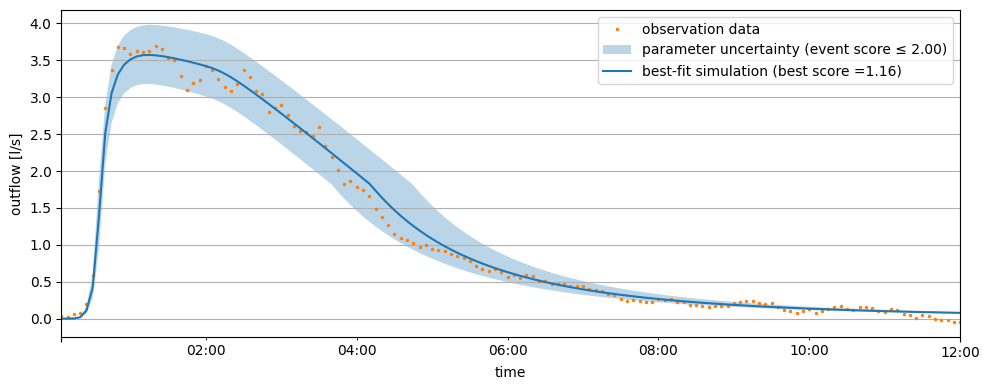

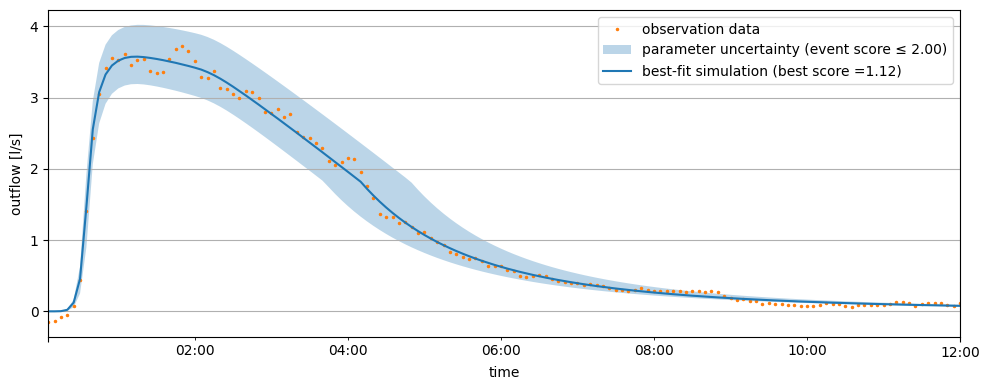

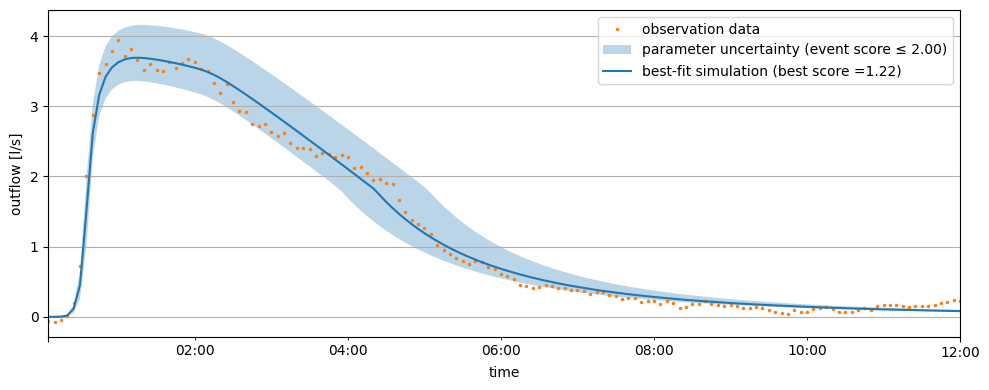

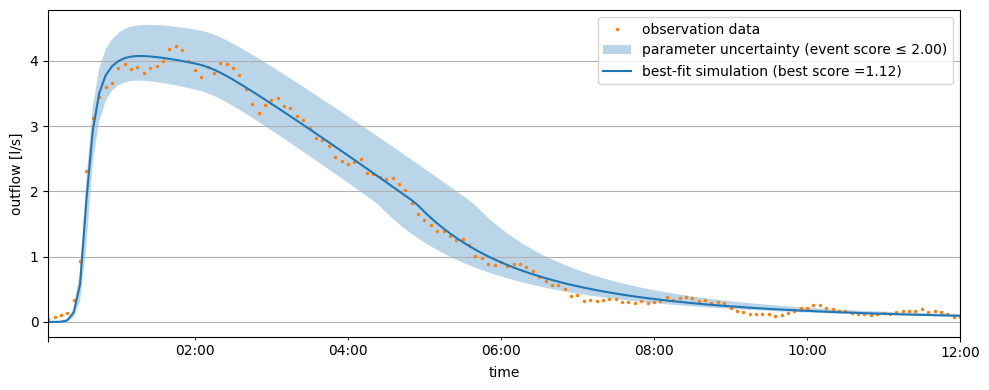

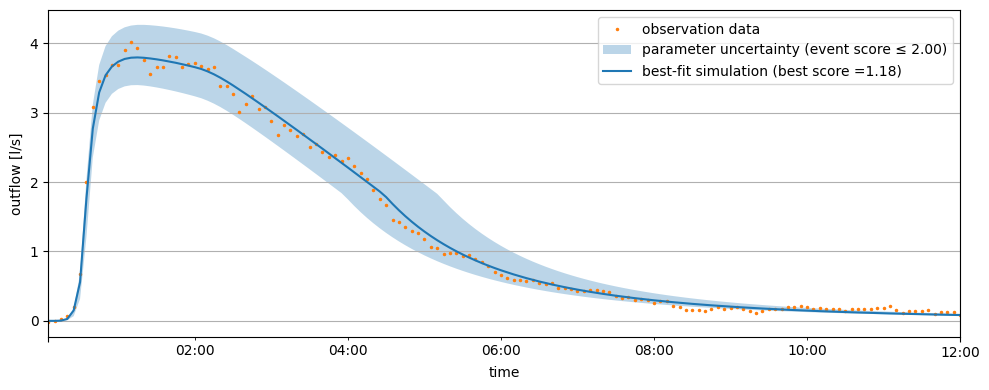

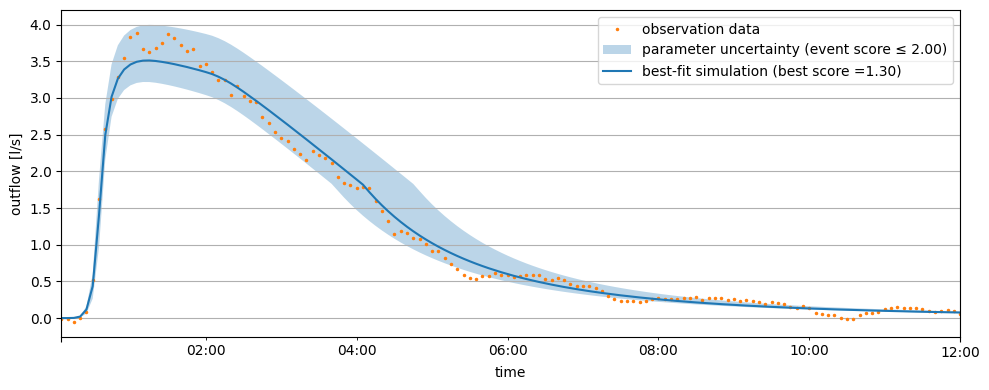

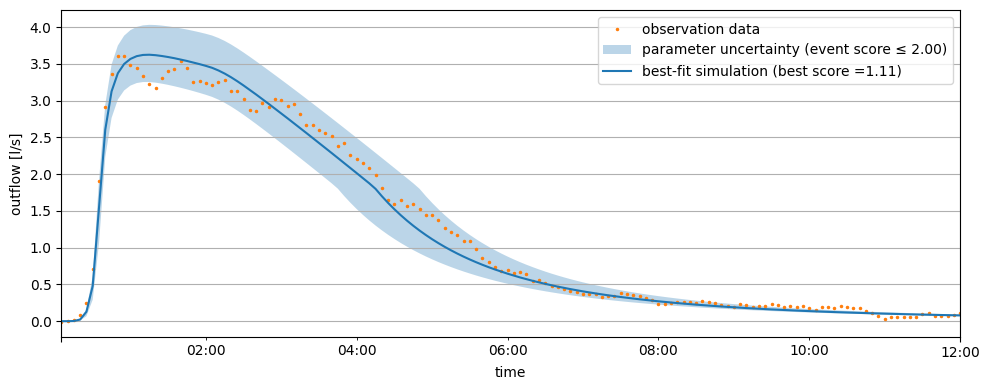

In [20]:
from pathlib import Path
import shutil
import json

def message_content(msg):
    """Works for both dict messages and LangChain message objects."""
    if isinstance(msg, dict):
        return msg.get("content", "")
    return getattr(msg, "content", str(msg))

if __name__ == "__main__":

    n_runs = 10
    output_root = Path(f"multi_run_outputs_{EXPERIMENT_MODE}")
    output_root.mkdir(exist_ok=True)   

    run_summaries = []

    for run_id in range(1, n_runs + 1):

        # --------------------------------------------------------
        # Completely reset shared workflow state
        # --------------------------------------------------------
        STATE = CalibrationState()        

        # End-to-end workflow timer
        run_start = time.perf_counter()
        
        print(f"\n{'=' * 80}")
        print(f"STARTING SUPERVISOR RUN {run_id}/{n_runs}")
        print(f"{'=' * 80}\n")

        run_dir = output_root / f"run_{run_id:02d}"
        run_dir.mkdir(exist_ok=True)

        dbname =  f"data_interim_SCE_UA_{EXPERIMENT_MODE}_run_{run_id:02d}"

        user_prompt = ( "Calibrate the SWMM-model 'Detention_Pond_Model.inp' with a synthetic observation time series at node O2 using SPOTPY and a combined event score of nse, volume and peak deviation." 
    "Load and prepare the model, generate synthetic observation data, remove subcatchments in predevelopment state and run the calibration with 2007-01-01 05:00 as end date."
    "Select appropriate settings for SPOTPY, perform the calibration, and evaluate the model quality and uncertainty."
                      f"Use the SPOTPY database name '{dbname}' so that this run is saved separately.")

        last_chunk = None

        for chunk in supervisor.stream(
            {
                "messages": [
                    {
                        "role": "user",
                        "content": user_prompt,
                    }
                ]
            },
        ):
            last_chunk = chunk
            pretty_print_messages(chunk, last_message=True)

        if last_chunk is None:
            raise RuntimeError(f"No output received from supervisor in run {run_id}.")

        final_message_history = last_chunk["supervisor"]["messages"]
        last = final_message_history[-1]
        final_text = message_content(last)

        print("\nFINAL SUPERVISOR MESSAGE:\n")
        print(final_text)

        # Save final supervisor message
        final_message_file = run_dir / "final_supervisor_message.txt"
        final_message_file.write_text(final_text, encoding="utf-8")

        # Save full message history as text
        history_file = run_dir / "message_history.txt"
        with history_file.open("w", encoding="utf-8") as f:
            for m in convert_to_messages(final_message_history):
                f.write(m.pretty_repr())
                f.write("\n\n")

        # Save STATE.df_results, if available
        if getattr(STATE, "df_results", None) is not None:
            state_results_file = run_dir / "STATE_df_results.csv"
            STATE.df_results.to_csv(state_results_file, index=False)

        # Copy calibration CSV created by run_spotpy_calibration
        csv_file = Path(f"{dbname}_final_calibration_results.csv")
        if csv_file.exists():
            shutil.copy2(csv_file, run_dir / csv_file.name)

        raw_spotpy_file = Path(f"{dbname}.csv")
        if raw_spotpy_file.exists():
            shutil.copy2(raw_spotpy_file, run_dir / raw_spotpy_file.name)

        # Copy calibration result plot, if analyze_calibration_results created it
        plot_file = Path("calib_results.png")
        if plot_file.exists():
            shutil.copy2(plot_file, run_dir / "calib_results.png")

        run_runtime_s = time.perf_counter() - run_start

        n_evaluations = (
            len(STATE.df_results)
            if getattr(STATE, "df_results", None) is not None
            else None
        )
        
        # Save compact run summary
        summary = {
            "run_id": run_id,
            "dbname": dbname,
            "run_dir": str(run_dir),
            "best_index": getattr(STATE, "best_index", None),
            "best_score": getattr(STATE, "best_score", None),
            "best_parameters": getattr(STATE, "best_parameters", None),

             # ---------------------------------------------
             # Runtime metrics
             # ---------------------------------------------
             "workflow_runtime_s": run_runtime_s,

             "swmm_simulations_total":
             getattr(STATE, "swmm_simulation_count", None),

             "swmm_runtime_total_s":
             getattr(STATE, "swmm_runtime_total_s", None),

             "calibration_runtime_s":
             getattr(STATE, "calibration_runtime_s", None),

             "calibration_swmm_simulations":
             getattr(STATE, "calibration_swmm_simulations", None),

             "calibration_swmm_runtime_s":
             getattr(STATE, "calibration_swmm_runtime_s", None),

             "spotpy_evaluations": n_evaluations,
             "final_message_file": str(final_message_file),
        }

        # -------------------------------------------------
        # Derived runtime metrics
        # -------------------------------------------------

        # Mean runtime of one SWMM simulation during calibration
        if (STATE.calibration_swmm_simulations and STATE.calibration_swmm_runtime_s is not None):
            summary["mean_swmm_runtime_s"] = (STATE.calibration_swmm_runtime_s/ STATE.calibration_swmm_simulations)
        else:
            summary["mean_swmm_runtime_s"] = None
            
        # Workflow time not spent inside SWMM
        summary["workflow_non_swmm_runtime_s"] = (run_runtime_s - STATE.swmm_runtime_total_s)

        # -------------------------------------------------
        # Store run summary
        # -------------------------------------------------
        run_summaries.append(summary)

        with (run_dir / "run_summary.json").open("w", encoding="utf-8") as f:
            json.dump(summary, f, indent=2)

    # Save overview of all 10 runs
    df_summary = pd.DataFrame(run_summaries)
    df_summary.to_csv(output_root / "all_run_summaries.csv", index=False)

    with (output_root / "all_run_summaries.json").open("w", encoding="utf-8") as f:
        json.dump(run_summaries, f, indent=2)

    print("\nAll simulation runs complete.")
    print(f"Results saved in: {output_root.resolve()}")


In [21]:
time_elapsed = (time.perf_counter() - time_start)
memMb=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024.0/1024.0
print ("%5.1f secs %5.1f MByte" % (time_elapsed,memMb))

5229.7 secs   0.2 MByte
